## Test the three Way 1 Multinomial Classification

In [1]:
import pandas as pd
import numpy as np

dementia_features_df = pd.read_csv('../../data/classification/3_mainconcept_features_dem_qsub.csv') 
aphasia_features_df = pd.read_csv('../../data/classification/3_mainconcept_features_aph_qsub.csv')
controls_features_df = pd.read_csv('../../data/classification/3_mainconcept_features_ctr_qsub.csv')   # Replace with the actual filename
print(controls_features_df.info())
  # Replace with the actual filename
print(dementia_features_df.info())
print(aphasia_features_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113 entries, 0 to 112
Data columns (total 24 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   participant                             113 non-null    object 
 1   total_utterances                        113 non-null    int64  
 2   distance_to_centroid                    113 non-null    float64
 3   num_unique_main_concepts                113 non-null    int64  
 4   num_total_main_concepts                 113 non-null    int64  
 5   unique_main_concept_match_ratio         113 non-null    float64
 6   total_main_concept_match_ratio          113 non-null    float64
 7   sequence_score_mainconcept              113 non-null    float64
 8   local_coherence_mainconcept             113 non-null    float64
 9   global_coherence_mainconcept            113 non-null    float64
 10  num_topic_switching                     113 non-null    int64 

In [2]:
participants_df = pd.read_csv('../../data/classification/combined_patient_data_111725.csv')  
print(participants_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Corpus             309 non-null    object 
 1   participant        309 non-null    object 
 2   age                302 non-null    object 
 3   sex                309 non-null    object 
 4   diagnosis          309 non-null    object 
 5   WAB score          102 non-null    float64
 6   standardized MOCA  132 non-null    float64
 7   gen_diagnosis      309 non-null    object 
dtypes: float64(2), object(6)
memory usage: 19.4+ KB
None


In [3]:
# Conditionally create combined ID only if Participant_Code starts with a numerical value (digit)
participants_df['combined_id'] = np.where(
    participants_df['participant'].str[0].str.isdigit(),
    participants_df['Corpus'].str.lower().str.strip() + participants_df['participant'].str.strip(),
    participants_df['participant'].str.strip()  # Fallback to just participant code if condition not met
)

participants_df['combined_id'] = participants_df['combined_id'].str.lower()

# Output the combined IDs
print(participants_df['combined_id'].tolist())

['delaware02-1', 'delaware03-1', 'delaware04-1', 'delaware05-1', 'delaware07-1', 'delaware08-1', 'delaware101-1', 'delaware12-1', 'delaware13-1', 'delaware200-1', 'delaware201-1', 'delaware203-1', 'delaware204-1', 'delaware208-1', 'delaware209-1', 'delaware214-1', 'delaware218-1', 'delaware220-1', 'delaware221-1', 'delaware224-1', 'delaware225-1', 'delaware226-1', 'delaware227-1', 'delaware228-1', 'delaware229-1', 'delaware233-1', 'delaware234-1', 'delaware235-1', 'delaware24-1', 'delaware244-1', 'delaware25-1', 'delaware270-1', 'delaware271-1', 'delaware276-1', 'delaware278-1', 'delaware279-1', 'delaware29-1', 'delaware30-1', 'delaware35-1', 'delaware36-1', 'delaware37-1', 'delaware38-1', 'delaware39-1', 'delaware42-1', 'delaware44-1', 'delaware45-1', 'delaware46-1', 'delaware48-1', 'delaware60-1', 'delaware62-1', 'delaware65-1', 'delaware67-1', 'delaware70-1', 'delaware77-1', 'delaware81-1', 'delaware84-1', 'delaware86-1', 'delaware87-1', 'delaware90-1', 'delaware92-1', 'delaware93-1

In [4]:
aphasia_df = participants_df[participants_df['gen_diagnosis'] == 'Aphasia']
dementia_df = participants_df[participants_df['gen_diagnosis'] == 'Dementia']
controls_df = participants_df[participants_df['gen_diagnosis'] == 'Control']
print(dementia_df.info())
print(aphasia_df.info())
print(controls_df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 94 entries, 113 to 206
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Corpus             94 non-null     object 
 1   participant        94 non-null     object 
 2   age                87 non-null     object 
 3   sex                94 non-null     object 
 4   diagnosis          94 non-null     object 
 5   WAB score          0 non-null      float64
 6   standardized MOCA  66 non-null     float64
 7   gen_diagnosis      94 non-null     object 
 8   combined_id        94 non-null     object 
dtypes: float64(2), object(7)
memory usage: 7.3+ KB
None
<class 'pandas.core.frame.DataFrame'>
Index: 102 entries, 207 to 308
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Corpus             102 non-null    object 
 1   participant        102 non-null    object 
 2   age              

In [5]:
aphasia_features_df['participant'] = aphasia_features_df['participant'].str.lower()
dementia_features_df['participant'] = dementia_features_df['participant'].str.lower()
controls_features_df['participant'] = controls_features_df['participant'].str.lower()

In [6]:
# unique IDs from each side
p_ids = set(aphasia_df['combined_id'])
f_ids = set(aphasia_features_df['participant'])
print(len(p_ids)), 
print(len(f_ids))

# who is in participants_df but NOT in controls_features_df
missing_in_features = p_ids - f_ids

# who is in controls_features_df but NOT in participants_df
missing_in_participants = f_ids - p_ids

print("Missing in aphasia_features_df:", missing_in_features)
print("Missing in participants_df:", missing_in_participants)

102
102
Missing in aphasia_features_df: set()
Missing in participants_df: set()


In [7]:
from collections import Counter
dementia_features_df = pd.read_csv('../../data/classification/dementia_mainconcept_features_update_qsub.csv')  
dementia_features_df['participant'] = dementia_features_df['participant'].str.lower()# Conditionally create combined ID only if Participant_Code starts with a numerical value (digit)
dementia_features_df['participant'] = np.where(
    dementia_features_df['participant'].str[0].str.isdigit(),
    "delaware"+ dementia_features_df['participant'].str.strip(),
    dementia_features_df['participant'].str.strip()  # Fallback to just participant code if condition not met
)

print(dementia_features_df['participant'].tolist())
print(len(dementia_features_df))

missing_in_metadata = Counter(dementia_features_df['participant']) 
print(missing_in_metadata)

['baycrest11634', 'delaware22-1', 'rbn7927a', 'delaware75-1', 'delaware64-1', 'baycrest12828', 'jre5043a', 'baycrest2103', 'delaware32-1', 'delaware23-1', 'delaware232-1', 'due3951a', 'delaware18-1', 'baycrest8538', 'baycrest12756', 'bdy3628a', 'baycrest12814', 'kcr7045a', 'delaware19-1', 'delaware277-1', 'delaware47-1', 'delaware50-1', 'delaware14-1', 'delaware216-1', 'bmn3031b', 'bbw8512a', 'delaware52-1', 'lby4645a', 'delaware58-1', 'dcr7644a', 'delaware59-1', 'baycrest11976', 'delaware88-1', 'mvs4058a', 'rcl5752', 'delaware01-1', 'delaware09-1', 'delaware10-1', 'delaware17-1', 'emh9057a', 'amr6628a', 'jks7696a', 'delaware11-1', 'tbd4254a', 'delaware31-1', 'delaware95-1', 'hwn0674a', 'delaware54-1', 'delaware61-1', 'delaware63-1', 'jbh5314a', 'delaware79-1', 'delaware68-1', 'lrw4117a', 'delaware43-1', 'baycrest12257', 'delaware16-1', 'delaware21-1', 'delaware34-1', 'chp4775a', 'delaware27-1', 'nhe3782a', 'delaware71-1', 'baycrest12813', 'delaware78-1', 'delaware06-1', 'bfi6092a', 'd

In [8]:
# unique IDs from each side
p_ids = set(dementia_df['combined_id'])
f_ids = set(dementia_features_df['participant'])

# who is in participants_df but NOT in controls_features_df
missing_in_features = p_ids - f_ids

# who is in controls_features_df but NOT in participants_df
missing_in_participants = f_ids - p_ids

print("Missing in dementia_features_df:", missing_in_features)
print("Missing in participants_df:", missing_in_participants)

Missing in dementia_features_df: set()
Missing in participants_df: set()


In [9]:
aphasia_df['participant'] = aphasia_df['combined_id']
aphasia_df = aphasia_df.drop(columns=['combined_id'])

aphasia_combined_df = pd.merge(aphasia_df, aphasia_features_df, on='participant', how='inner')
print(len(aphasia_df))
print(len(aphasia_features_df))
aphasia_combined_df.info()

102
102
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102 entries, 0 to 101
Data columns (total 31 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Corpus                                  102 non-null    object 
 1   participant                             102 non-null    object 
 2   age                                     102 non-null    object 
 3   sex                                     102 non-null    object 
 4   diagnosis                               102 non-null    object 
 5   WAB score                               102 non-null    float64
 6   standardized MOCA                       0 non-null      float64
 7   gen_diagnosis                           102 non-null    object 
 8   total_utterances                        102 non-null    int64  
 9   distance_to_centroid                    102 non-null    float64
 10  num_unique_main_concepts                102 non-null  

/scratch/ipykernel_3114562/3901510765.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  aphasia_df['participant'] = aphasia_df['combined_id']


In [10]:
dementia_df['participant'] = dementia_df['combined_id']
dementia_df = dementia_df.drop(columns=['combined_id'])

dementia_combined_df = pd.merge(dementia_df, dementia_features_df, on='participant', how='inner')
print(len(dementia_df))
# print(len(dementia_features_df))
dementia_combined_df.info()

94
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 31 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Corpus                                  94 non-null     object 
 1   participant                             94 non-null     object 
 2   age                                     87 non-null     object 
 3   sex                                     94 non-null     object 
 4   diagnosis                               94 non-null     object 
 5   WAB score                               0 non-null      float64
 6   standardized MOCA                       66 non-null     float64
 7   gen_diagnosis                           94 non-null     object 
 8   total_utterances                        94 non-null     int64  
 9   distance_to_centroid                    94 non-null     float64
 10  num_unique_main_concepts                94 non-null     int64

/scratch/ipykernel_3114562/2793744067.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dementia_df['participant'] = dementia_df['combined_id']


In [11]:
controls_df['participant'] = controls_df['combined_id']
controls_df = controls_df.drop(columns=['combined_id'])

controls_combined_df = pd.merge(controls_df, controls_features_df, on='participant', how='inner')
controls_combined_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113 entries, 0 to 112
Data columns (total 31 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Corpus                                  113 non-null    object 
 1   participant                             113 non-null    object 
 2   age                                     113 non-null    object 
 3   sex                                     113 non-null    object 
 4   diagnosis                               113 non-null    object 
 5   WAB score                               0 non-null      float64
 6   standardized MOCA                       66 non-null     float64
 7   gen_diagnosis                           113 non-null    object 
 8   total_utterances                        113 non-null    int64  
 9   distance_to_centroid                    113 non-null    float64
 10  num_unique_main_concepts                113 non-null    int64 

/scratch/ipykernel_3114562/245591086.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  controls_df['participant'] = controls_df['combined_id']


In [12]:
all_df = pd.concat([dementia_combined_df, aphasia_combined_df, controls_combined_df], ignore_index=True)
all_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 31 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Corpus                                  309 non-null    object 
 1   participant                             309 non-null    object 
 2   age                                     302 non-null    object 
 3   sex                                     309 non-null    object 
 4   diagnosis                               309 non-null    object 
 5   WAB score                               102 non-null    float64
 6   standardized MOCA                       132 non-null    float64
 7   gen_diagnosis                           309 non-null    object 
 8   total_utterances                        309 non-null    int64  
 9   distance_to_centroid                    309 non-null    float64
 10  num_unique_main_concepts                309 non-null    int64 

In [13]:
columns_to_drop = ['sex','Corpus','WAB score', 'diagnosis', 'age', 'standardized MOCA', ]
num_df = all_df.drop(columns=columns_to_drop)
num_cols = num_df.columns
print(num_cols)

Index(['participant', 'gen_diagnosis', 'total_utterances',
       'distance_to_centroid', 'num_unique_main_concepts',
       'num_total_main_concepts', 'unique_main_concept_match_ratio',
       'total_main_concept_match_ratio', 'sequence_score_mainconcept',
       'local_coherence_mainconcept', 'global_coherence_mainconcept',
       'num_topic_switching', 'ratio_topic_switching_percent',
       'num_missing_referent', 'ratio_missing_referent_percent',
       'num_tangential_utterance', 'ratio_tangential_utterance_percent',
       'num_propositional_repetition',
       'ratio_propositional_repetition_percent', 'num_filler',
       'ratio_filler_percent', 'num_conceptual_incongruence',
       'ratio_conceptual_incongruence_percent', 'num_coherent',
       'ratio_coherent_percent'],
      dtype='object')


In [14]:
aph_df = num_df[num_df['gen_diagnosis'] == 'Aphasia']
dem_df = num_df[num_df['gen_diagnosis'] == 'Dementia']
ctrl_df = num_df[num_df['gen_diagnosis'] == 'Control']


print(f"Number of patients: {len(aph_df)}")
print(f"Number of controls: {len(dem_df)}")
print(f"Number of controls: {len(ctrl_df)}")

Number of patients: 102
Number of controls: 94
Number of controls: 113


In [15]:
import numpy as np
import pandas as pd

# columns to scale: all numeric except the label column(s)
num_cols = num_df.select_dtypes(include='number').columns.tolist()
for c in ['group']:
    if c in num_cols:
        num_cols.remove(c)

# fit params on the whole df
means = num_df[num_cols].mean()
stds  = num_df[num_cols].std(ddof=0).replace(0, np.nan)  # avoid div-by-zero

# normalized copy
df_z = all_df.copy()
df_z[num_cols] = (num_df[num_cols] - means) / stds

# if you prefer to keep zero-variance columns as 0 instead of NaN:
df_z[num_cols] = df_z[num_cols].fillna(0)

# split back to groups (normalized)
dem_df_z = df_z[df_z['gen_diagnosis'] == 'Dementia'].copy()
aph_df_z = df_z[df_z['gen_diagnosis'] == 'Aphasia'].copy()
ctl_df_z = df_z[df_z['gen_diagnosis'] == 'Control'].copy()

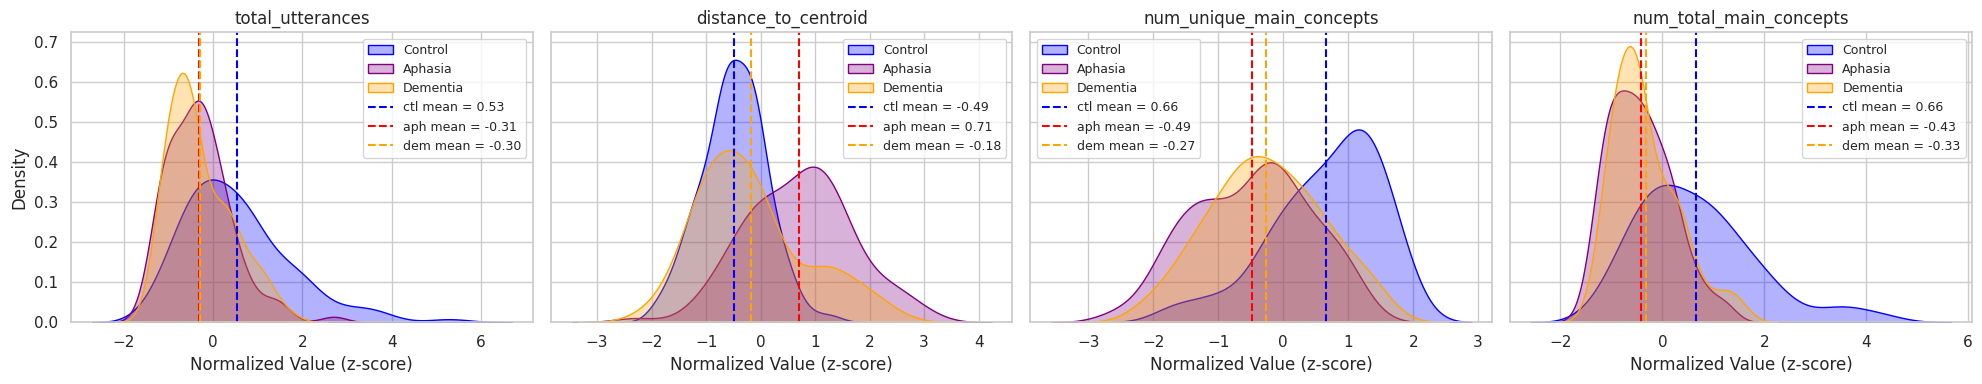

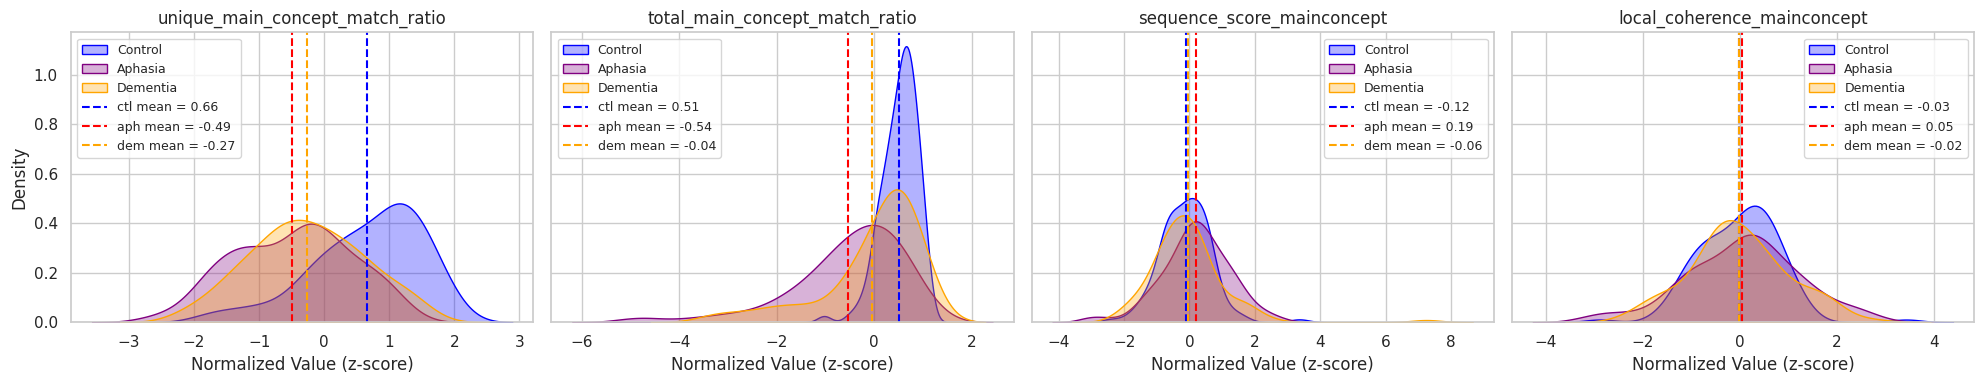

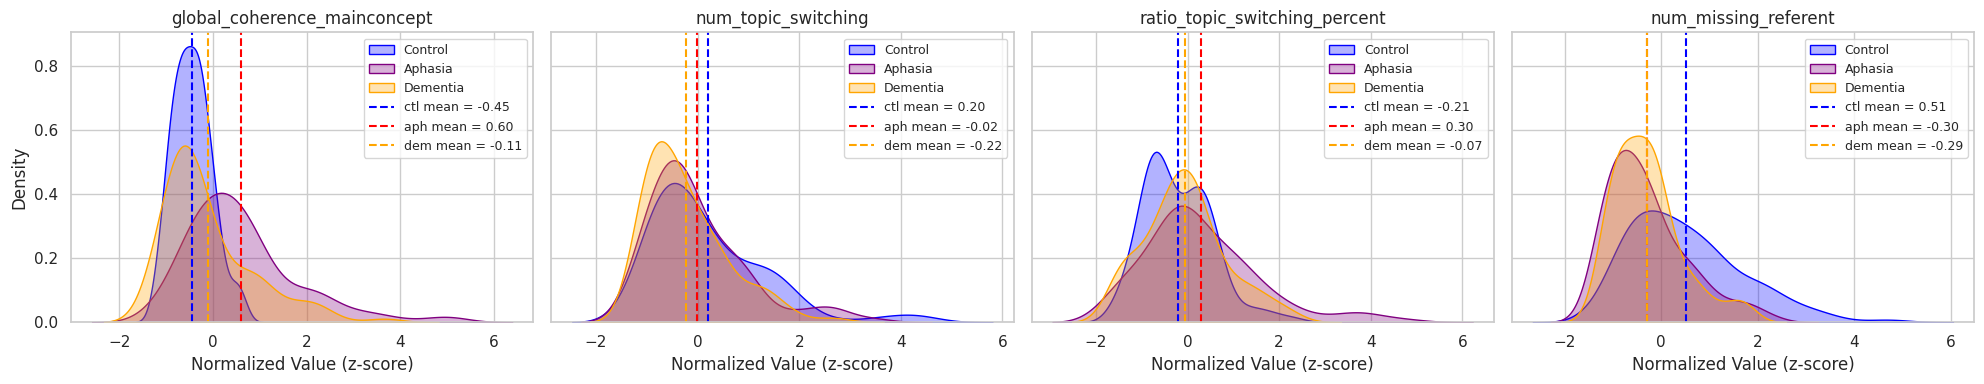

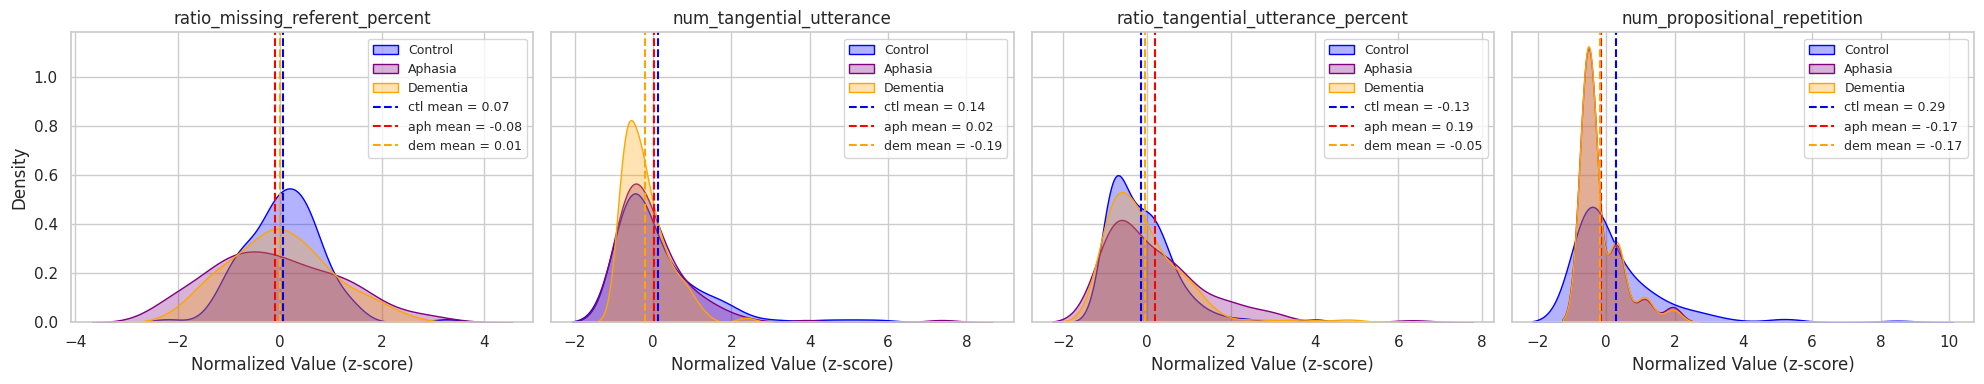

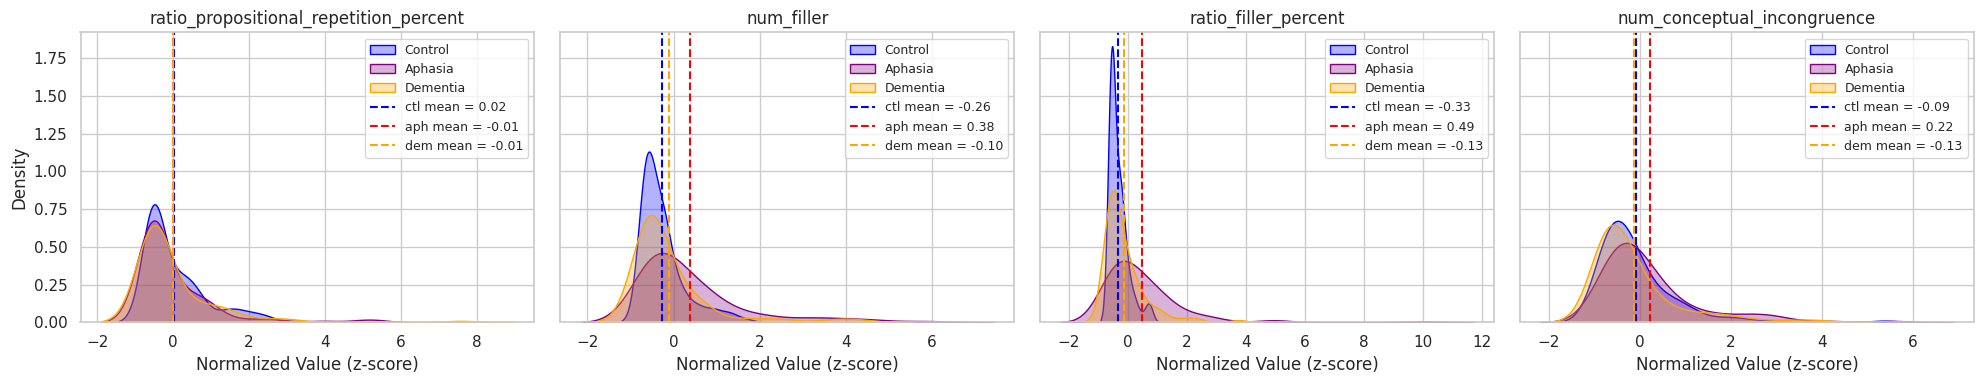

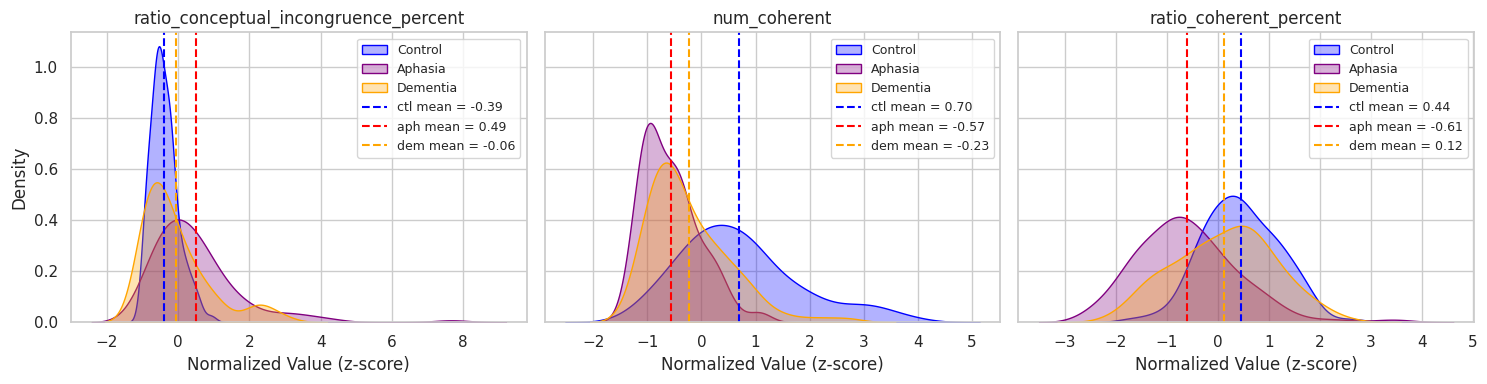

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

plots_per_row = 4

for i in range(0, len(num_cols), plots_per_row):
    cols_batch = num_cols[i:i + plots_per_row]

    fig, axes = plt.subplots(
        1, len(cols_batch),
        figsize=(5 * len(cols_batch), 4),
        sharey=True
    )

    # Handle case where there's only one subplot
    if len(cols_batch) == 1:
        axes = [axes]

    for ax, col in zip(axes, cols_batch):

        # ✅ Controls (Blue)
        sns.kdeplot(
            data=ctl_df_z,
            x=col,
            fill=True,
            alpha=0.3,
            color='blue',
            label='Control',
            ax=ax
        )

        # Aphasia (Purple)
        sns.kdeplot(
            data=aph_df_z,
            x=col,
            fill=True,
            alpha=0.3,
            color='red',
            label='Aphasia',
            ax=ax
        )

        # Dementia (Orange)
        sns.kdeplot(
            data=dem_df_z,
            x=col,
            fill=True,
            alpha=0.3,
            color='orange',
            label='Dementia',
            ax=ax
        )

        # ✅ Means
        mean_ctl = ctl_df_z[col].mean()
        mean_aph = aph_df_z[col].mean()
        mean_dem = dem_df_z[col].mean()

        # Control mean
        ax.axvline(
            mean_ctl,
            color='blue',
            linestyle='--',
            linewidth=1.5,
            label=f'ctl mean = {mean_ctl:.2f}'
        )

        # Aphasia mean
        ax.axvline(
            mean_aph,
            color='red',
            linestyle='--',
            linewidth=1.5,
            label=f'aph mean = {mean_aph:.2f}'
        )

        # Dementia mean
        ax.axvline(
            mean_dem,
            color='orange',
            linestyle='--',
            linewidth=1.5,
            label=f'dem mean = {mean_dem:.2f}'
        )

        ax.set_title(col)
        ax.set_xlabel('Normalized Value (z-score)')
        ax.set_ylabel('Density')

        # Legend
        ax.legend(fontsize=9)

    fig.tight_layout()
    plt.show()


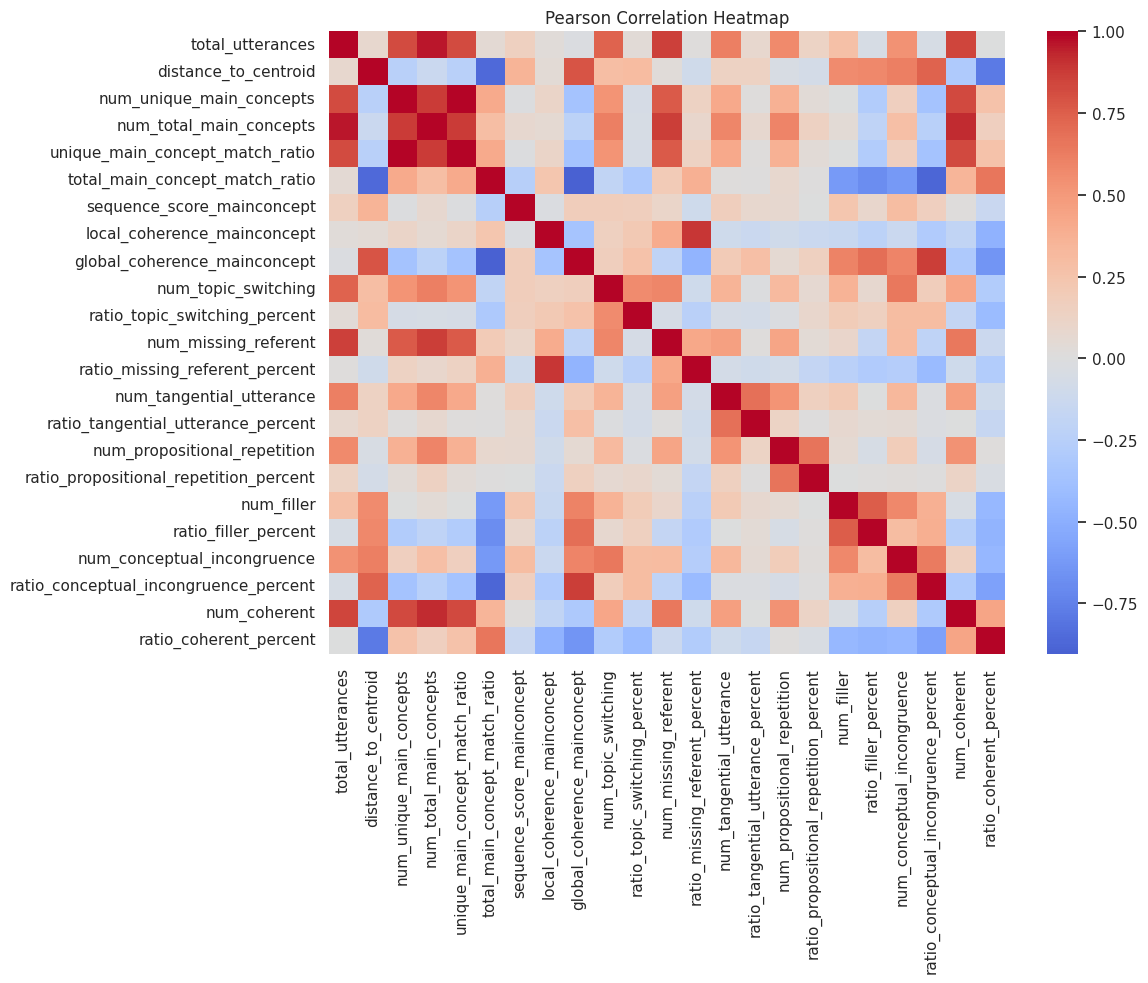

In [17]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Compute Pearson correlation
corr = num_df.corr(numeric_only=True)

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=False, cmap='coolwarm', center=0)
plt.title("Pearson Correlation Heatmap")
plt.tight_layout()
plt.show()

In [18]:
import numpy as np

# Take absolute values
corr_abs = corr.abs()

# Mask the diagonal (self correlations)
np.fill_diagonal(corr_abs.values, 0)

# Find pairs above threshold
high_corr_pairs = np.where(corr_abs > 0.8)

pairs = []
for i, j in zip(*high_corr_pairs):
    if i < j:  # avoid duplicates
        pairs.append((
            corr.index[i],
            corr.columns[j],
            corr.iloc[i, j]   # original (signed) correlation value
        ))

for a, b, r in pairs:
    print(f"{a}  <-->  {b}   r = {r:.3f}")

total_utterances  <-->  num_unique_main_concepts   r = 0.819
total_utterances  <-->  num_total_main_concepts   r = 0.956
total_utterances  <-->  unique_main_concept_match_ratio   r = 0.819
total_utterances  <-->  num_missing_referent   r = 0.863
total_utterances  <-->  num_coherent   r = 0.846
distance_to_centroid  <-->  total_main_concept_match_ratio   r = -0.856
num_unique_main_concepts  <-->  num_total_main_concepts   r = 0.877
num_unique_main_concepts  <-->  unique_main_concept_match_ratio   r = 1.000
num_unique_main_concepts  <-->  num_coherent   r = 0.835
num_total_main_concepts  <-->  unique_main_concept_match_ratio   r = 0.877
num_total_main_concepts  <-->  num_missing_referent   r = 0.868
num_total_main_concepts  <-->  num_coherent   r = 0.921
unique_main_concept_match_ratio  <-->  num_coherent   r = 0.835
total_main_concept_match_ratio  <-->  global_coherence_mainconcept   r = -0.905
total_main_concept_match_ratio  <-->  ratio_conceptual_incongruence_percent   r = -0.879
loca

In [19]:
cols_to_remove = []
cols_to_remove.extend([
    "total_utterances",
    "num_unique_main_concepts",
    "num_total_main_concepts",
    "local_coherence_mainconcept",
    "global_coherence_mainconcept",
    "num_coherent",
    # "ratio_conceptual_incongruence_percent",
    "total_main_concept_match_ratio",
])

df_clean = num_df.drop(columns=cols_to_remove, errors="ignore")
feature_cols = df_clean.columns

corr = df_clean.corr(numeric_only=True)

In [20]:
import numpy as np

# Take absolute values
corr_abs = corr.abs()

# Mask the diagonal (self correlations)
np.fill_diagonal(corr_abs.values, 0)

# Find pairs above threshold
high_corr_pairs = np.where(corr_abs > 0.8)

pairs = []
for i, j in zip(*high_corr_pairs):
    if i < j:  # avoid duplicates
        pairs.append((
            corr.index[i],
            corr.columns[j],
            corr.iloc[i, j]   # original (signed) correlation value
        ))

for a, b, r in pairs:
    print(f"{a}  <-->  {b}   r = {r:.3f}")


## Logistic Regression Classification

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# 1) build training df from RAW (unscaled) data, NOT df_z
df_ml = all_df.drop(columns=cols_to_remove + columns_to_drop, errors='ignore').copy()
df_ml = df_ml[df_ml['gen_diagnosis'].isin(['Control', 'Aphasia', 'Dementia'])].copy()

# 2) explicit multiclass labels
label_map = {'Control': 0, 'Aphasia': 1, 'Dementia': 2}
df_ml['label'] = df_ml['gen_diagnosis'].map(label_map)

participants = df_ml['participant']  # keep separately if you want

X = df_ml.drop(columns=['gen_diagnosis', 'label', 'participant'], errors='ignore')
y = df_ml['label'].astype(int)

# 3) split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 4) scale on TRAIN only + train multinomial LR
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(
        multi_class="multinomial",   # ✅ true 3-class softmax
        solver="lbfgs",
        max_iter=5000,
        class_weight="balanced"      # optional; good if class imbalance
    ))
])

pipe.fit(X_train, y_train)
pred = pipe.predict(X_test)

print(confusion_matrix(y_test, pred))
print(classification_report(
    y_test, pred,
    target_names=["Control", "Aphasia", "Dementia"]
))


[[17  0  6]
 [ 0 15  5]
 [ 3  5 11]]
              precision    recall  f1-score   support

     Control       0.85      0.74      0.79        23
     Aphasia       0.75      0.75      0.75        20
    Dementia       0.50      0.58      0.54        19

    accuracy                           0.69        62
   macro avg       0.70      0.69      0.69        62
weighted avg       0.71      0.69      0.70        62



/projectnb/skiran/Cassie/Code/miniconda3/envs/myenv/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


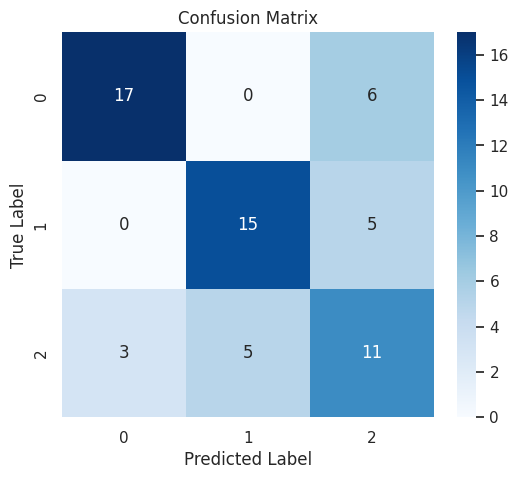

In [22]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

In [23]:
import numpy as np
from sklearn.metrics import roc_auc_score

# after fitting your pipeline:
proba = pipe.predict_proba(X_test)   # shape: (n_samples, 3) aligned to pipe.classes_
classes = pipe.named_steps['lr'].classes_  # should be [0,1,2]

# helper: pairwise AUC between class a and b
def pairwise_auc(y_true, proba, a, b):
    mask = np.isin(y_true, [a, b])
    y_bin = (y_true[mask] == b).astype(int)      # "positive" = b
    score = proba[mask, b]                       # probability of class b
    return roc_auc_score(y_bin, score)

y_true = y_test.to_numpy() if hasattr(y_test, "to_numpy") else np.array(y_test)

auc_ctl_aph = pairwise_auc(y_true, proba, 0, 1)  # Control vs Aphasia
auc_ctl_dem = pairwise_auc(y_true, proba, 0, 2)  # Control vs Dementia
auc_aph_dem = pairwise_auc(y_true, proba, 1, 2)  # Aphasia vs Dementia

print(f"AUC(Control vs Aphasia):  {auc_ctl_aph:.3f}")
print(f"AUC(Control vs Dementia): {auc_ctl_dem:.3f}")
print(f"AUC(Aphasia vs Dementia): {auc_aph_dem:.3f}")


AUC(Control vs Aphasia):  0.917
AUC(Control vs Dementia): 0.707
AUC(Aphasia vs Dementia): 0.653


In [24]:
from sklearn.metrics import roc_auc_score

ovo_auc = roc_auc_score(y_test, proba, multi_class="ovo", average="macro")
print("Multiclass OvO AUC (macro):", round(ovo_auc, 3))

Multiclass OvO AUC (macro): 0.813


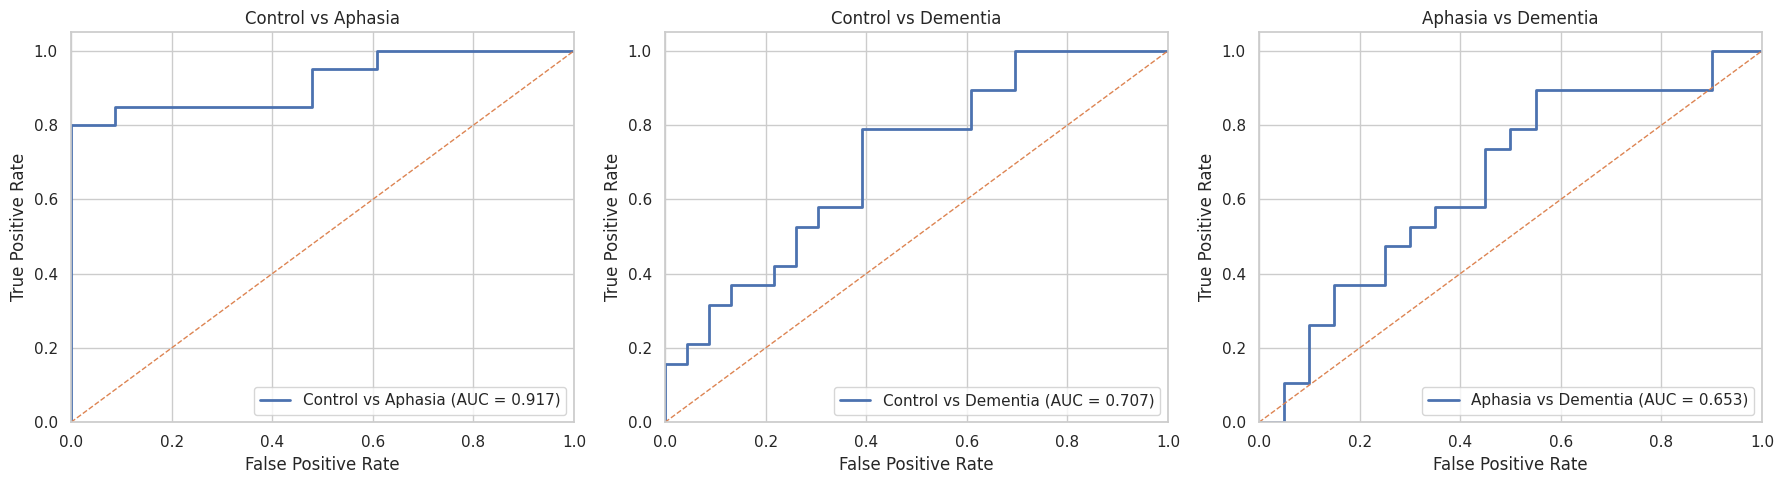

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Get predicted probabilities
proba = pipe.predict_proba(X_test)
y_true = np.array(y_test)

# Class mapping
class_names = {
    0: "Control",
    1: "Aphasia",
    2: "Dementia"
}

# Helper: plot ROC for a pair
def plot_pairwise_roc(y, proba, a, b, ax):

    # keep only samples from class a or b
    mask = np.isin(y, [a, b])

    y_bin = (y[mask] == b).astype(int)   # b = positive class
    scores = proba[mask, b]

    fpr, tpr, _ = roc_curve(y_bin, scores)
    roc_auc = auc(fpr, tpr)

    ax.plot(fpr, tpr, lw=2,
            label=f"{class_names[a]} vs {class_names[b]} (AUC = {roc_auc:.3f})")

    ax.plot([0, 1], [0, 1], linestyle="--", lw=1)

    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1.05])
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right")


# -------- Plot all 3 pairs -------- #

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Control vs Aphasia
plot_pairwise_roc(y_true, proba, 0, 1, axes[0])
axes[0].set_title("Control vs Aphasia")

# Control vs Dementia
plot_pairwise_roc(y_true, proba, 0, 2, axes[1])
axes[1].set_title("Control vs Dementia")

# Aphasia vs Dementia
plot_pairwise_roc(y_true, proba, 1, 2, axes[2])
axes[2].set_title("Aphasia vs Dementia")

plt.tight_layout()
plt.show()


In [26]:
import numpy as np
import pandas as pd

lr = pipe.named_steps['lr']
W = lr.coef_          # shape: (3, n_features)
b = lr.intercept_     # shape: (3,)
features = X.columns.to_list()

class_names = {0:"Control", 1:"Aphasia", 2:"Dementia"}
classes = lr.classes_  # should be array([0,1,2])


In [27]:
def pairwise_coef_df(i, j, top_k=20):
    # coefficients for log(P(j)/P(i))
    w = W[np.where(classes==j)[0][0]] - W[np.where(classes==i)[0][0]]
    bb = b[np.where(classes==j)[0][0]] - b[np.where(classes==i)[0][0]]

    df = pd.DataFrame({
        "feature": features,
        "coef": w,
        "abs_coef": np.abs(w)
    }).sort_values("abs_coef", ascending=False)

    return df.head(top_k), bb


In [28]:
top_ctl_aph, b_ctl_aph = pairwise_coef_df(0, 1, top_k=20)  # Aphasia vs Control
top_ctl_dem, b_ctl_dem = pairwise_coef_df(0, 2, top_k=20)  # Dementia vs Control
top_aph_dem, b_aph_dem = pairwise_coef_df(1, 2, top_k=20)  # Dementia vs Aphasia

print("Aphasia vs Control intercept diff:", b_ctl_aph)
print(top_ctl_aph.head(10))


Aphasia vs Control intercept diff: 0.32859984564737593
                                   feature      coef  abs_coef
0                     distance_to_centroid  1.910415  1.910415
5                     num_missing_referent -1.026663  1.026663
10  ratio_propositional_repetition_percent  0.898202  0.898202
9             num_propositional_repetition -0.861503  0.861503
13             num_conceptual_incongruence -0.777723  0.777723
11                              num_filler  0.733873  0.733873
1          unique_main_concept_match_ratio -0.642920  0.642920
7                 num_tangential_utterance  0.633381  0.633381
15                  ratio_coherent_percent -0.277615  0.277615
8       ratio_tangential_utterance_percent -0.277422  0.277422


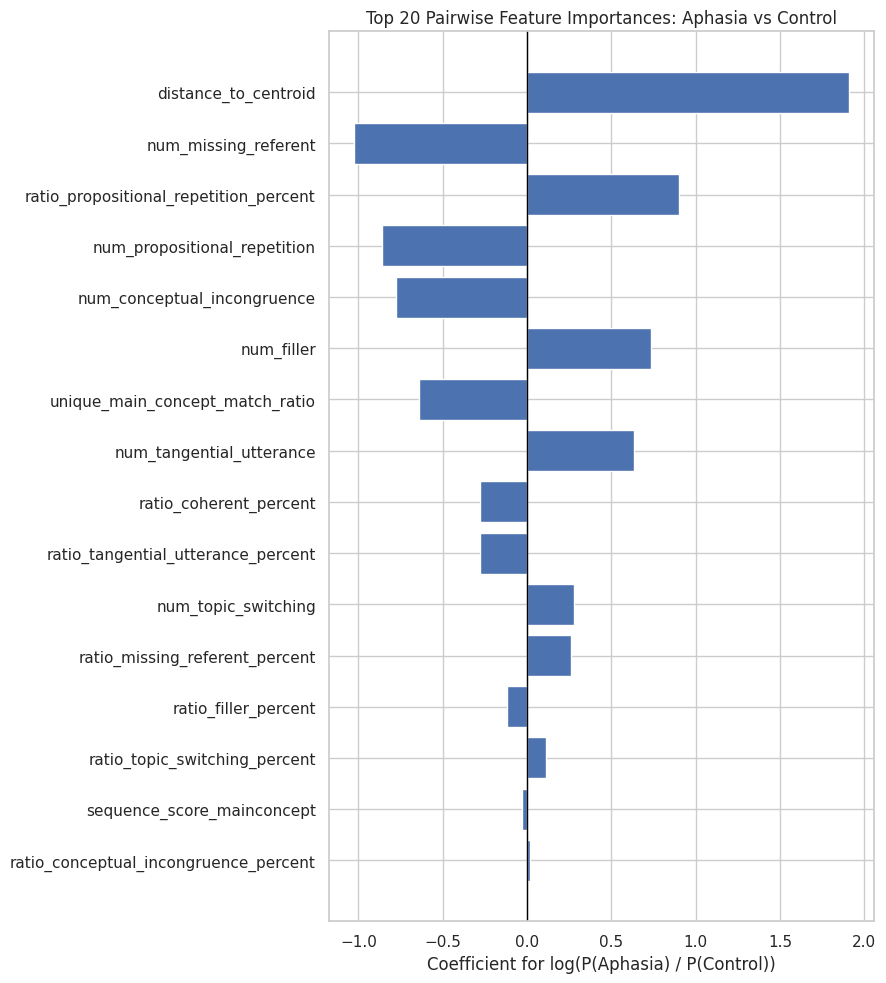

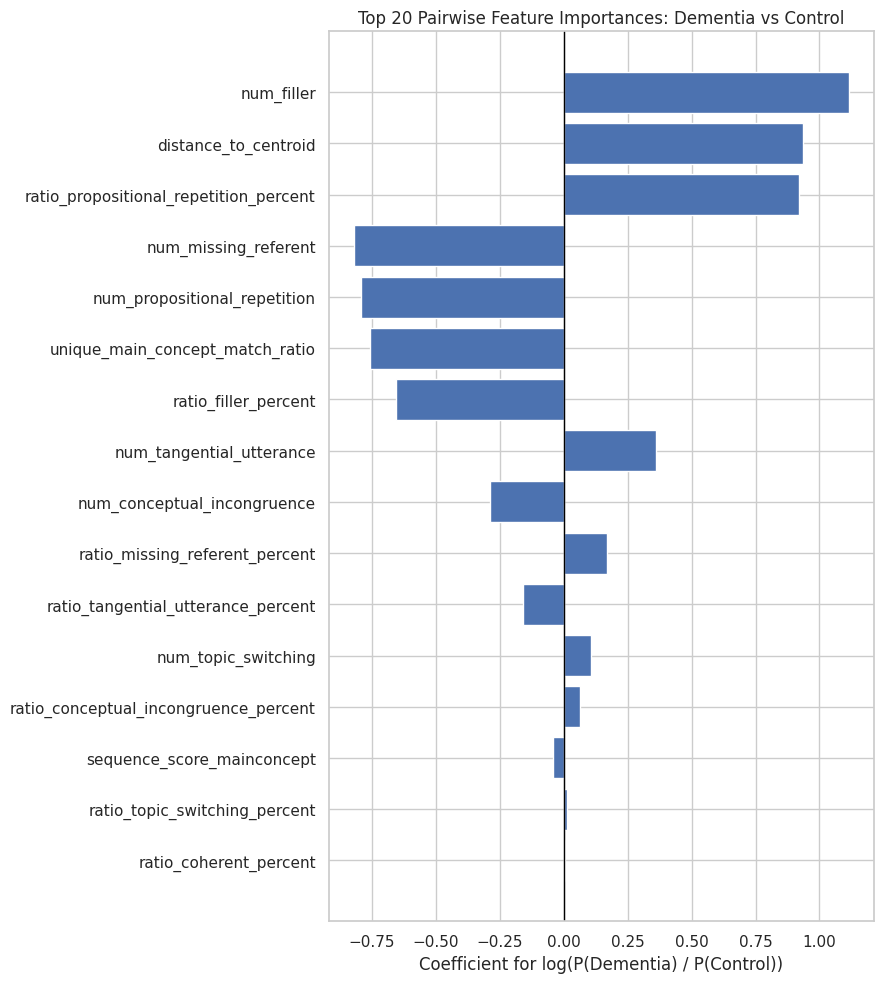

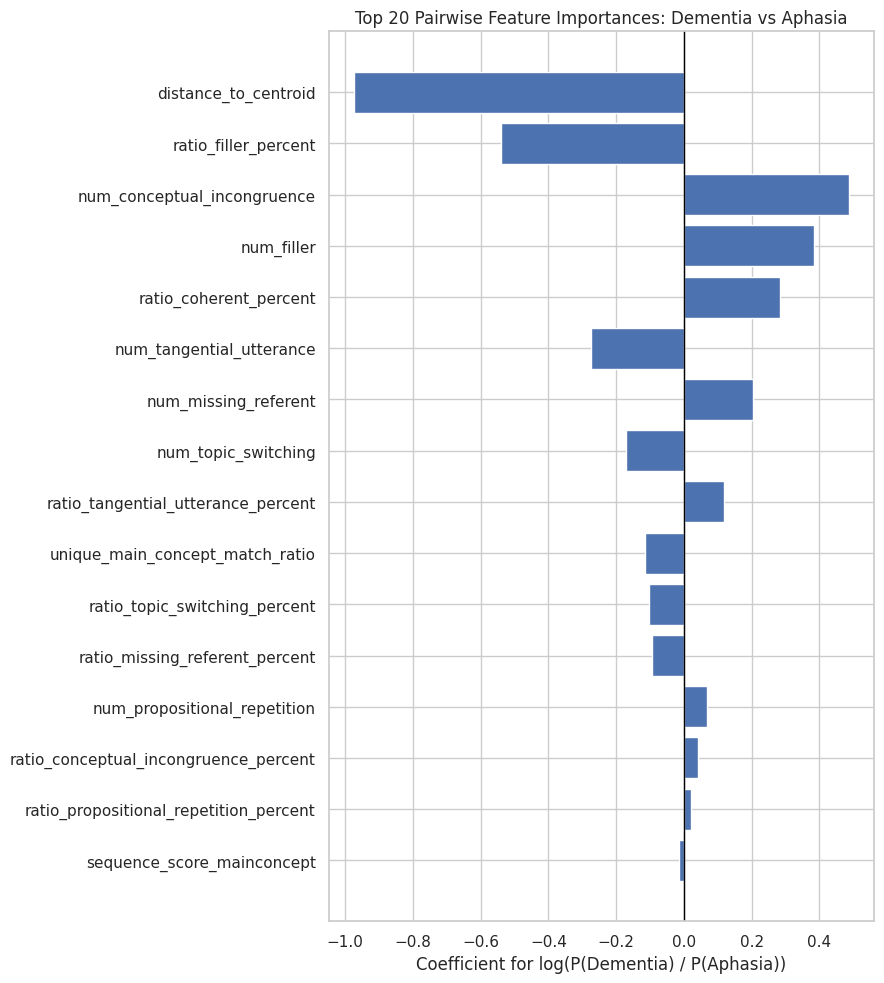

In [29]:
import matplotlib.pyplot as plt

def plot_pairwise_importance(i, j, top_k=20):
    df, _ = pairwise_coef_df(i, j, top_k=top_k)
    df = df.iloc[::-1]  # reverse for barh

    plt.figure(figsize=(9, 10))
    plt.barh(df["feature"], df["coef"])
    plt.axvline(0, color="black", lw=1)
    plt.xlabel(f"Coefficient for log(P({class_names[j]}) / P({class_names[i]}))")
    plt.title(f"Top {top_k} Pairwise Feature Importances: {class_names[j]} vs {class_names[i]}")
    plt.tight_layout()
    plt.show()

plot_pairwise_importance(0, 1, top_k=20)  # Aphasia vs Control
plot_pairwise_importance(0, 2, top_k=20)  # Dementia vs Control
plot_pairwise_importance(1, 2, top_k=20)  # Dementia vs Aphasia


## 5 Fold cross validation


===== 5-FOLD CV START =====

Fold 1 3-class accuracy: 0.645
Fold 2 3-class accuracy: 0.581
Fold 3 3-class accuracy: 0.613
Fold 4 3-class accuracy: 0.548
Fold 5 3-class accuracy: 0.574

===== 5-FOLD CV DONE =====

===== 3-CLASS ACCURACY (5 folds) =====
Accuracy per fold: [0.645 0.581 0.613 0.548 0.574]
Mean accuracy: 0.592
Std accuracy:  0.034


/projectnb/skiran/Cassie/Code/miniconda3/envs/myenv/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/projectnb/skiran/Cassie/Code/miniconda3/envs/myenv/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/projectnb/skiran/Cassie/Code/miniconda3/envs/myenv/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/projectnb/skiran/Cass

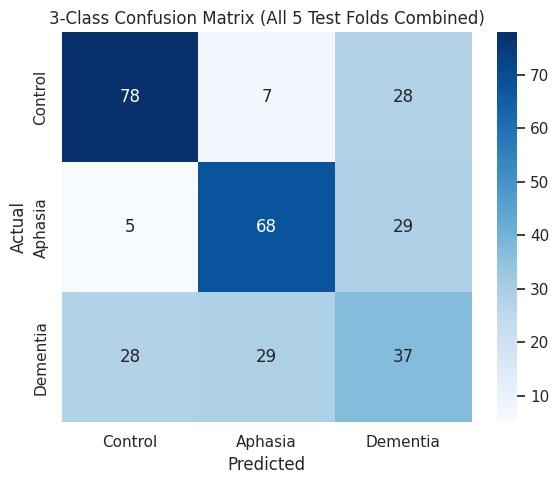

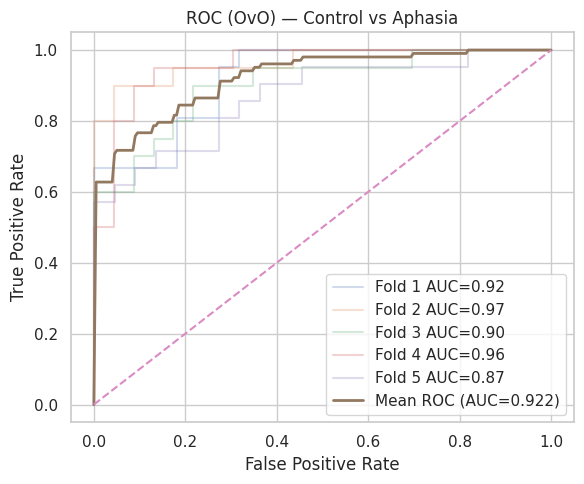

Control vs Aphasia AUC per fold: [0.92  0.965 0.902 0.957 0.868]  Mean: 0.922


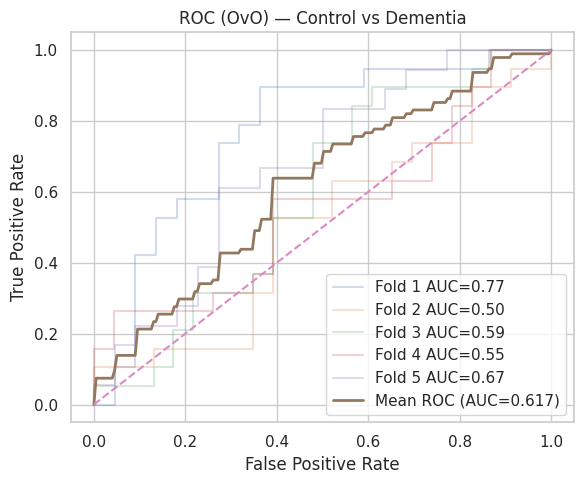

Control vs Dementia AUC per fold: [0.768 0.499 0.59  0.551 0.674]  Mean: 0.617


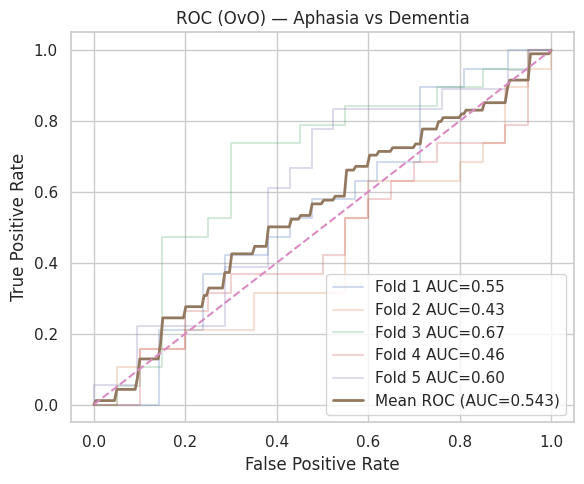

Aphasia vs Dementia AUC per fold: [0.546 0.432 0.674 0.461 0.601]  Mean: 0.543


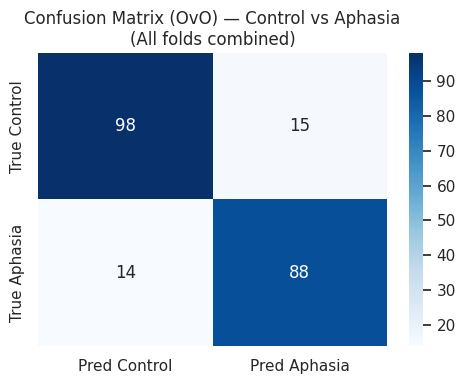

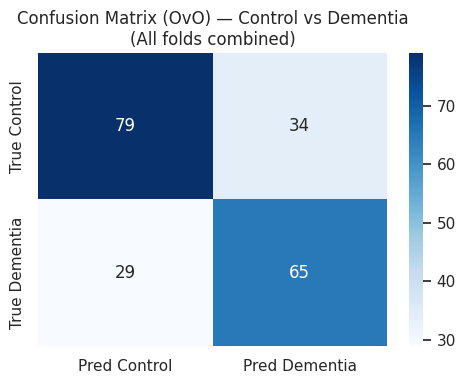

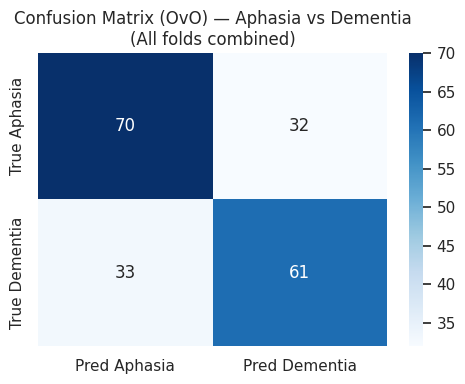

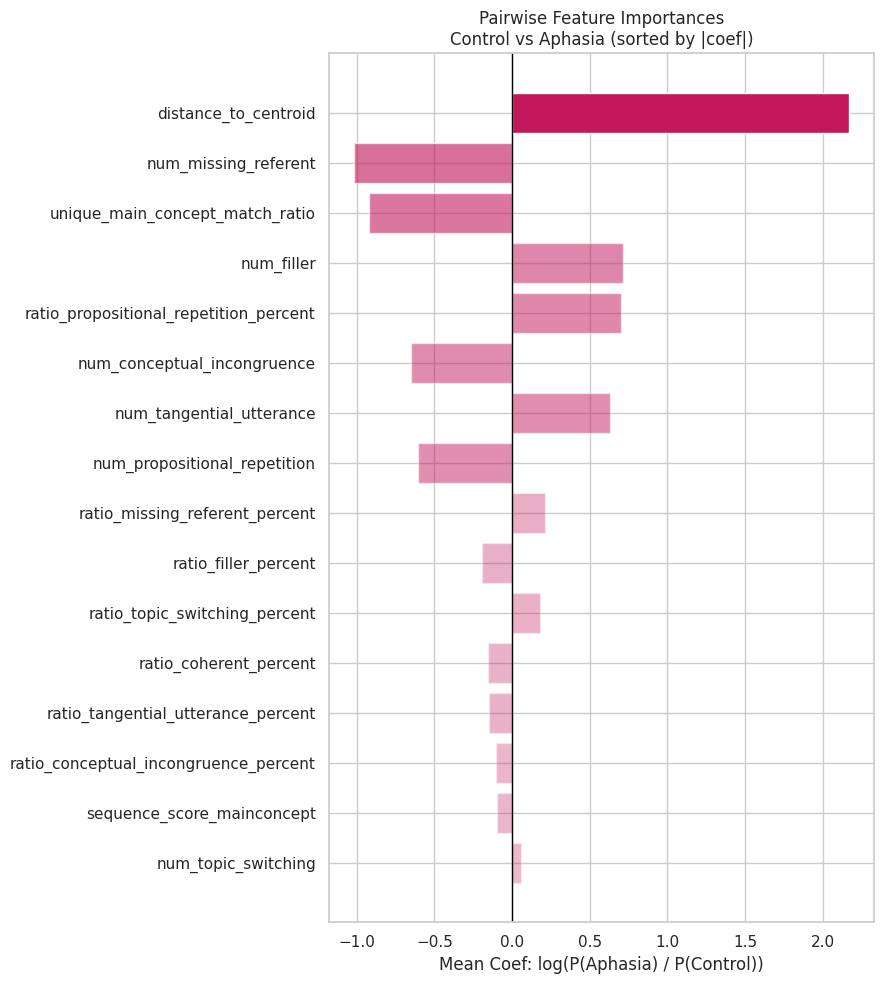

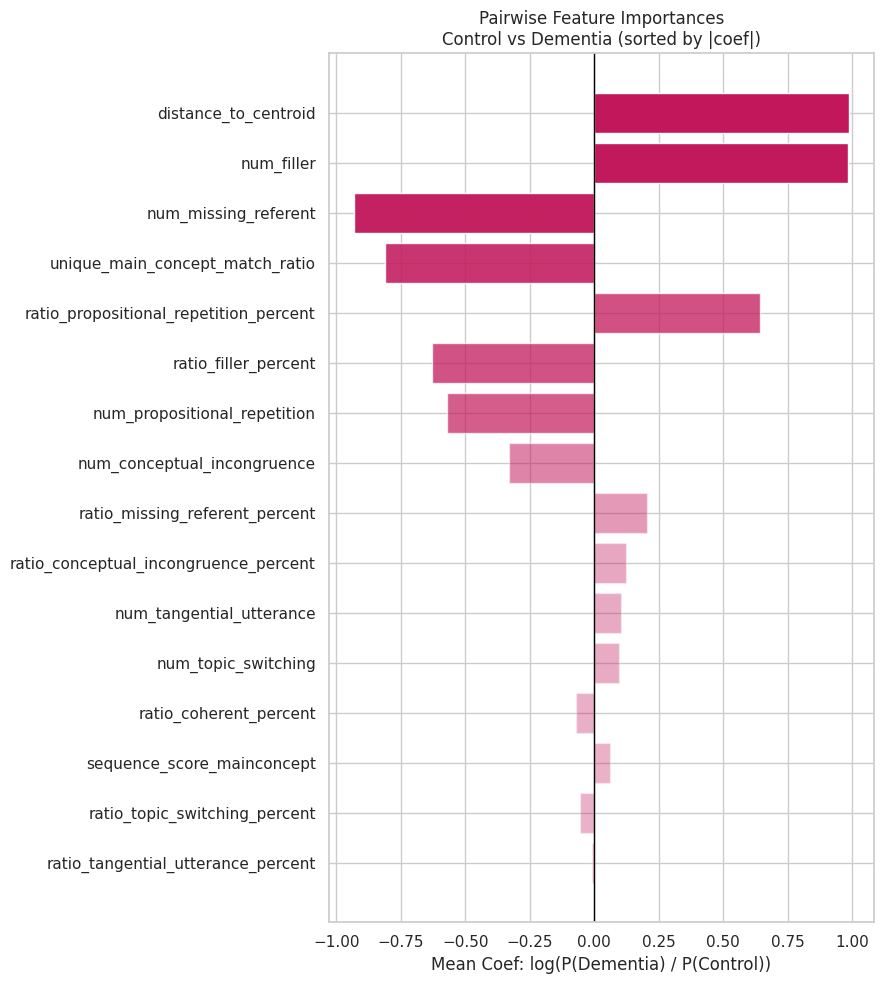

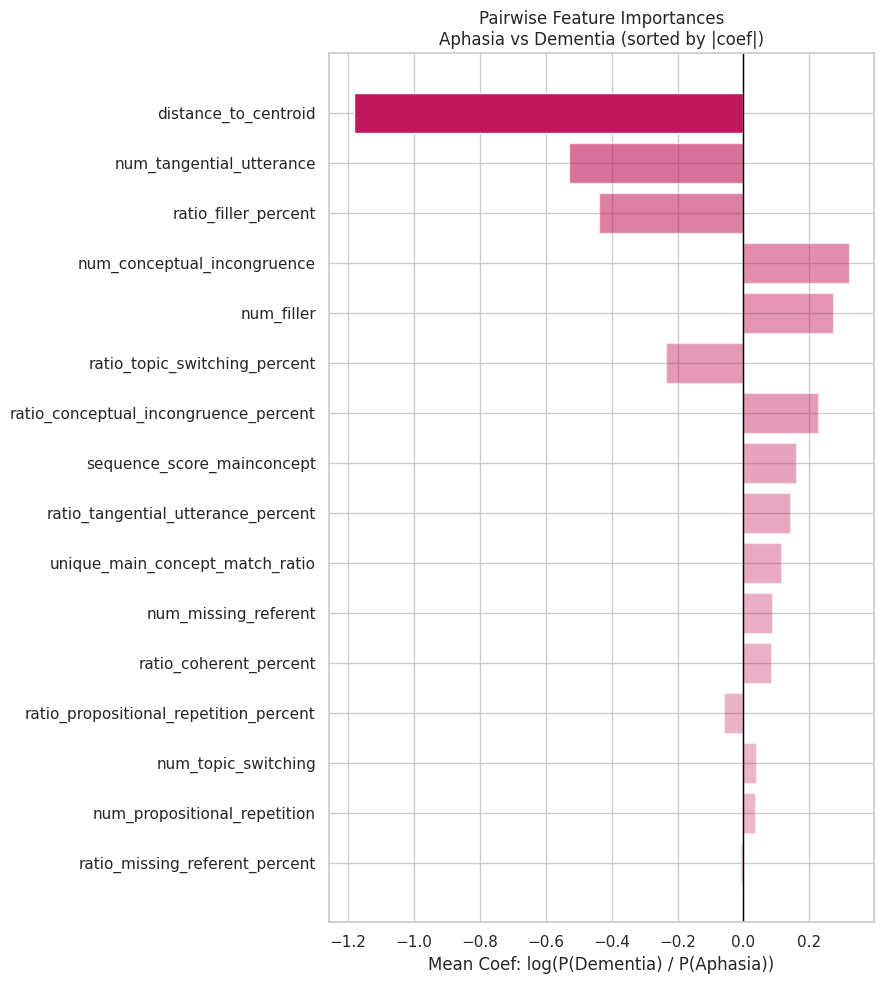

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, roc_auc_score, roc_curve
)

sns.set(style="whitegrid")

# ----------------------------
# Inputs you already have:
# X: features dataframe (no participant, no label, no gen_diagnosis)
# y: labels Series with 0=Control, 1=Aphasia, 2=Dementia
# participants: participant IDs aligned to X/y
# ----------------------------

class_names = {0:"Control", 1:"Aphasia", 2:"Dementia"}
pairs = [(0,1), (0,2), (1,2)]  # (Control vs Aphasia), (Control vs Dementia), (Aphasia vs Dementia)

# Model: scaling fit on TRAIN fold only
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(
        multi_class="multinomial",
        solver="lbfgs",
        max_iter=5000,
        class_weight="balanced"
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ---------- storage ----------
# multiclass (3-class) global confusion across all folds
y_true_all_3 = []
y_pred_all_3 = []
fold_acc_3 = []

# pairwise AUCs + ROC curves
pair_auc = {p: [] for p in pairs}
pair_fprs = {p: [] for p in pairs}
pair_tprs = {p: [] for p in pairs}
mean_fpr = np.linspace(0, 1, 200)
pair_mean_tpr = {p: np.zeros_like(mean_fpr) for p in pairs}

# pairwise global confusion across all folds + per-fold false pos/neg IDs
pair_y_true_all = {p: [] for p in pairs}
pair_y_pred_all = {p: [] for p in pairs}
pair_fold_results = {p: [] for p in pairs}

# pairwise coefficients per fold (directional): w_j - w_i
pair_coef_folds = {p: [] for p in pairs}
feature_names = X.columns.to_list()
multi_coef_folds = []

print("\n===== 5-FOLD CV START =====\n")

for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    ids_test = participants.iloc[test_idx] if hasattr(participants, "iloc") else participants[test_idx]

    # fit single 3-class model
    pipe.fit(X_train, y_train)

    # multiclass predictions
    y_pred_3 = pipe.predict(X_test)
    acc_fold = accuracy_score(y_test, y_pred_3)
    fold_acc_3.append(acc_fold)
    print(f"Fold {fold} 3-class accuracy: {acc_fold:.3f}")
    y_true_all_3.extend(y_test.tolist())
    y_pred_all_3.extend(y_pred_3.tolist())

    # predicted probabilities (aligned to lr.classes_)
    proba = pipe.predict_proba(X_test)
    lr = pipe.named_steps["lr"]
    # store multiclass coefs per fold (3 x n_features)
    multi_coef_folds.append(lr.coef_.copy())
    classes = lr.classes_  # expected [0,1,2] but we won't assume order

    # ---- Pairwise metrics from this one model ----
    for (i, j) in pairs:
        # mask test samples belonging to either class i or j
        mask = y_test.isin([i, j]).to_numpy()
        if mask.sum() == 0:
            continue

        y_pair_true = y_test.to_numpy()[mask]
        ids_pair = np.array(ids_test)[mask]

        # AUC: use prob of "positive class" j (consistent with your binary AUC usage)
        j_col = np.where(classes == j)[0][0]
        scores_j = proba[mask, j_col]

        # binarize: positive = j
        y_bin = (y_pair_true == j).astype(int)
        auc_ij = roc_auc_score(y_bin, scores_j)
        pair_auc[(i, j)].append(auc_ij)

        # ROC curve
        fpr, tpr, _ = roc_curve(y_bin, scores_j)
        pair_fprs[(i, j)].append(fpr)
        pair_tprs[(i, j)].append(tpr)
        pair_mean_tpr[(i, j)] += np.interp(mean_fpr, fpr, tpr)
        pair_mean_tpr[(i, j)][0] = 0.0

        # Pairwise predicted labels using only probs of {i, j}
        i_col = np.where(classes == i)[0][0]
        probs_ij = proba[mask][:, [i_col, j_col]]
        pred_pair = np.array([i, j])[np.argmax(probs_ij, axis=1)]

        # store for global pairwise confusion
        pair_y_true_all[(i, j)].extend(y_pair_true.tolist())
        pair_y_pred_all[(i, j)].extend(pred_pair.tolist())

        # false negatives / false positives relative to positive class j
        fn_mask = (y_pair_true == j) & (pred_pair == i)  # true j predicted i
        fp_mask = (y_pair_true == i) & (pred_pair == j)  # true i predicted j

        pair_fold_results[(i, j)].append({
            "fold": fold,
            "false_negatives": ids_pair[fn_mask].tolist(),
            "false_positives": ids_pair[fp_mask].tolist()
        })

        # Pairwise coefficients from multinomial LR: w_j - w_i (direction kept)
        w = lr.coef_[np.where(classes == j)[0][0]] - lr.coef_[np.where(classes == i)[0][0]]
        pair_coef_folds[(i, j)].append(w)

print("\n===== 5-FOLD CV DONE =====\n")

print("===== 3-CLASS ACCURACY (5 folds) =====")
print("Accuracy per fold:", np.round(fold_acc_3, 3))
print(f"Mean accuracy: {np.mean(fold_acc_3):.3f}")
print(f"Std accuracy:  {np.std(fold_acc_3):.3f}")


# =========================
# 1) 3-class global confusion matrix
# =========================
cm3 = confusion_matrix(y_true_all_3, y_pred_all_3, labels=[0,1,2])
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm3, annot=True, fmt="d", cmap="Blues",
    xticklabels=[class_names[k] for k in [0,1,2]],
    yticklabels=[class_names[k] for k in [0,1,2]]
)
plt.title("3-Class Confusion Matrix (All 5 Test Folds Combined)")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.show()


# =========================
# 2) Pairwise ROC curves (mean across folds) + AUC per fold
# =========================
for (i, j) in pairs:
    if len(pair_auc[(i, j)]) == 0:
        continue

    mean_tpr = pair_mean_tpr[(i, j)] / cv.n_splits
    mean_tpr[-1] = 1.0
    mean_auc = np.mean(pair_auc[(i, j)])

    plt.figure(figsize=(6, 5))

    # optional: fold curves
    for k, (fpr, tpr) in enumerate(zip(pair_fprs[(i, j)], pair_tprs[(i, j)]), start=1):
        plt.plot(fpr, tpr, alpha=0.25, label=f"Fold {k} AUC={pair_auc[(i,j)][k-1]:.2f}")

    # mean curve
    plt.plot(mean_fpr, mean_tpr, linewidth=2, label=f"Mean ROC (AUC={mean_auc:.3f})")
    plt.plot([0, 1], [0, 1], linestyle="--")

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC (OvO) — {class_names[i]} vs {class_names[j]}")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

    print(f"{class_names[i]} vs {class_names[j]} AUC per fold:", np.round(pair_auc[(i,j)], 3),
          " Mean:", round(mean_auc, 3))


# =========================
# 3) Pairwise global confusion matrices
# =========================
for (i, j) in pairs:
    yt = pair_y_true_all[(i, j)]
    yp = pair_y_pred_all[(i, j)]
    if len(yt) == 0:
        continue

    cm = confusion_matrix(yt, yp, labels=[i, j])

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=[f"Pred {class_names[i]}", f"Pred {class_names[j]}"],
        yticklabels=[f"True {class_names[i]}", f"True {class_names[j]}"],
    )
    plt.title(f"Confusion Matrix (OvO) — {class_names[i]} vs {class_names[j]}\n(All folds combined)")
    plt.tight_layout()
    plt.show()


# =========================
# 4) Pairwise feature importances (direction kept, sorted by abs magnitude)
#     coef_pair = w_j - w_i
# =========================
TOP_K = 20

for (i, j) in pairs:

    if len(pair_coef_folds[(i, j)]) == 0:
        continue

    W = np.vstack(pair_coef_folds[(i, j)])   # (n_folds, n_features)
    coef_mean = W.mean(axis=0)               # signed mean
    abs_mean = np.abs(coef_mean)

    imp = pd.DataFrame({
        "feature": feature_names,
        "coef_mean": coef_mean,
        "abs_coef_mean": abs_mean
    }).sort_values("abs_coef_mean", ascending=False)

    top = imp.head(TOP_K).iloc[::-1]

    # ✅ Normalize magnitude → opacity range [0.3, 1.0]
    mags = top["abs_coef_mean"].to_numpy()
    mags_norm = (mags - mags.min()) / (mags.max() - mags.min() + 1e-9)

    alphas = 0.3 + 0.7 * mags_norm   # min=0.3, max=1.0

    plt.figure(figsize=(9, 10))

    bars = plt.barh(
        top["feature"],
        top["coef_mean"],
        color="#C2185B"
    )

    # ✅ Apply per-bar opacity
    for bar, a in zip(bars, alphas):
        bar.set_alpha(a)

    plt.axvline(0, color="black", lw=1)

    plt.xlabel(
        f"Mean Coef: log(P({class_names[j]}) / P({class_names[i]}))"
    )

    plt.title(
        f"Pairwise Feature Importances\n"
        f"{class_names[i]} vs {class_names[j]} (sorted by |coef|)"
    )

    plt.tight_layout()
    plt.show()


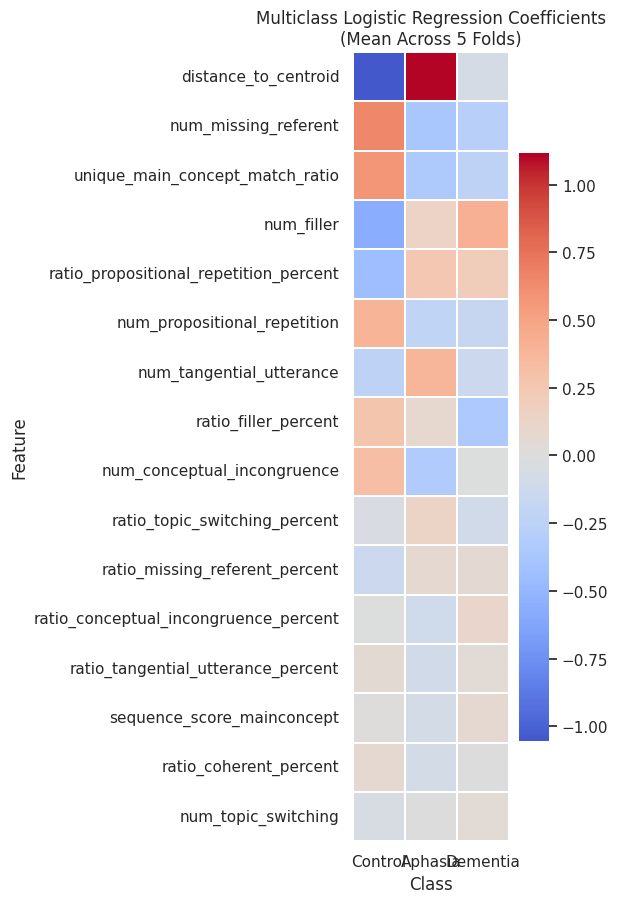

In [31]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# mean coef across folds: (3, n_features)
W_mean = np.mean(np.stack(multi_coef_folds), axis=0)

# pick top K features by max |coef|
importance = np.max(np.abs(W_mean), axis=0)
top_idx = np.argsort(importance)[-20:][::-1]   # top 20

feat_top = [feature_names[i] for i in top_idx]
coef_mat = W_mean[:, top_idx]                  # (3, K)

# transpose → rows=features, cols=classes
coef_df = pd.DataFrame(
    coef_mat.T,
    index=feat_top,
    columns=["Control", "Aphasia", "Dementia"]
)

plt.figure(figsize=(6, 0.45*len(feat_top) + 2))

sns.heatmap(
    coef_df,
    center=0,
    cmap="coolwarm",
    linewidths=0.3,
    linecolor="white"
)

plt.title("Multiclass Logistic Regression Coefficients\n(Mean Across 5 Folds)")
plt.xlabel("Class")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


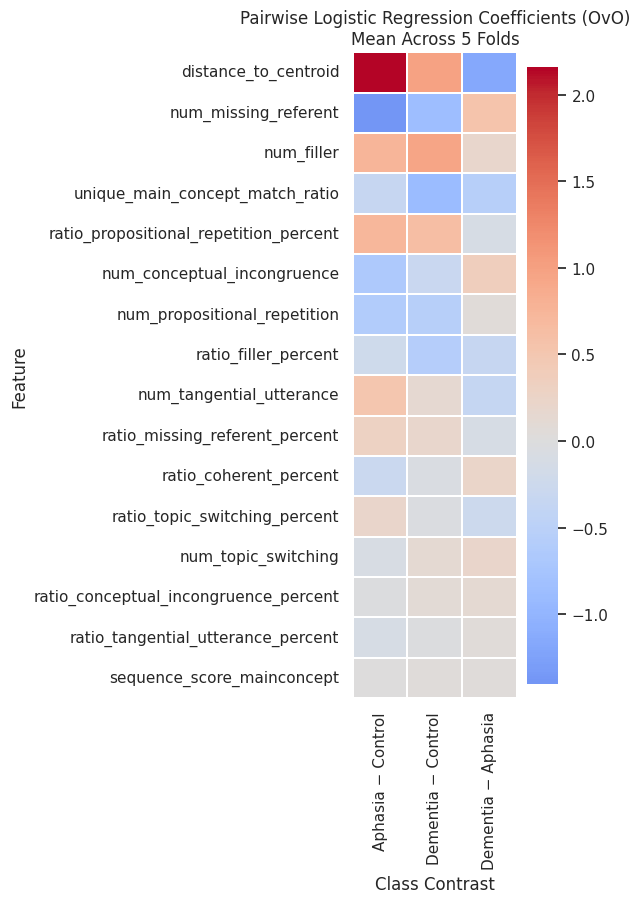

In [74]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

rows = []
col_labels = []

for (i, j) in pairs:

    W = np.vstack(pair_coef_folds[(i, j)])  # (folds, features)
    rows.append(W.mean(axis=0))

    col_labels.append(f"{class_names[j]} − {class_names[i]}")

pair_mat = np.vstack(rows)   # (3, n_features)

# top K by max |coef|
importance = np.max(np.abs(pair_mat), axis=0)
top_idx = np.argsort(importance)[-20:][::-1]

feat_top = [feature_names[i] for i in top_idx]
pair_top = pair_mat[:, top_idx]

# transpose: rows=features, cols=contrasts
pair_df = pd.DataFrame(
    pair_top.T,
    index=feat_top,
    columns=col_labels
)

plt.figure(figsize=(6, 0.45*len(feat_top) + 2))

sns.heatmap(
    pair_df,
    center=0,
    cmap="coolwarm",
    linewidths=0.3,
    linecolor="white"
)

plt.title("Pairwise Logistic Regression Coefficients (OvO)\nMean Across 5 Folds")
plt.xlabel("Class Contrast")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()
